In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# Create our house price dataset
data = {
    "Size_sqft": [800, 1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000],
    "Price_thousands": [150, 180, 210, 250, 290, 320, 350, 390, 430, 460],
}

In [2]:
# converting data into dataframe
df = pd.DataFrame(data)
df

,Size_sqft,Price_thousands
0,800,150
1,1000,180
2,1200,210
3,1500,250
4,1800,290
5,2000,320
6,2200,350
7,2500,390
8,2800,430
9,3000,460


In [3]:
# EDA

print("\n--- First 5 rows ---")
print(df.head())

print("\n--- Dataset shape ---")
print(df.shape)

print("\n--- Dataset information ---")
df.info()

print("\n--- Statistical summary ---")
print(df.describe())


--- First 5 rows ---
   Size_sqft  Price_thousands
0        800              150
1       1000              180
2       1200              210
3       1500              250
4       1800              290

--- Dataset shape ---
(10, 2)

--- Dataset information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Size_sqft        10 non-null     int64
 1   Price_thousands  10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes

--- Statistical summary ---
         Size_sqft  Price_thousands
count    10.000000        10.000000
mean   1880.000000       303.000000
std     756.894239       105.940235
min     800.000000       150.000000
25%    1275.000000       220.000000
50%    1900.000000       305.000000
75%    2425.000000       380.000000
max    3000.000000       460.000000


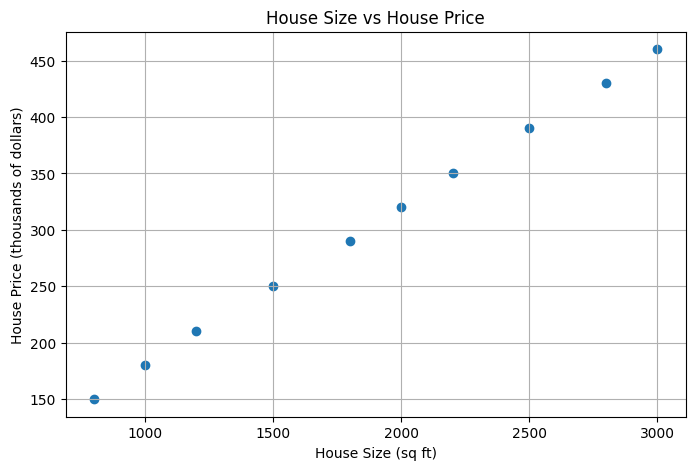

In [4]:
# visualize

plt.figure(figsize=(8, 5))

plt.scatter(df["Size_sqft"], df["Price_thousands"])

plt.title("House Size vs House Price")
plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price (thousands of dollars)")
plt.grid(True)

plt.show()

In [5]:
# Step 5: Separate features and target

X = df[["Size_sqft"]]
y = df["Price_thousands"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features (X):
   Size_sqft
0        800
1       1000
2       1200
3       1500
4       1800
5       2000
6       2200
7       2500
8       2800
9       3000

Target (y):
0    150
1    180
2    210
3    250
4    290
5    320
6    350
7    390
8    430
9    460
Name: Price_thousands, dtype: int64

X shape: (10, 1)
y shape: (10,)


In [6]:
# split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining features:")
print(X_train)

print("\nTesting features:")
print(X_test)

X_train shape: (6, 1)
X_test shape: (4, 1)
y_train shape: (6,)
y_test shape: (4,)

Training features:
   Size_sqft
7       2500
2       1200
9       3000
4       1800
3       1500
6       2200

Testing features:
   Size_sqft
8       2800
1       1000
5       2000
0        800


In [7]:
# train the model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_pred

array([432.03313253, 180.73795181, 320.34638554, 152.81626506])

In [8]:
# Comparing Actual price vs Predicted price

print("Actual Prices:")
print(y_test.to_numpy())

print("\nPredicted Prices:")
print(y_pred)

print("\nComparison of Actual vs Predicted Prices:")

results = pd.DataFrame(
    {
        "House_Size": X_test["Size_sqft"],
        "Actual_Price": y_test,
        "Predicted_Price": y_pred,
    }
)

print(results.round(2))

Actual Prices:
[430 180 320 150]

Predicted Prices:
[432.03313253 180.73795181 320.34638554 152.81626506]

Comparison of Actual vs Predicted Prices:
   House_Size  Actual_Price  Predicted_Price
8        2800           430           432.03
1        1000           180           180.74
5        2000           320           320.35
0         800           150           152.82


In [9]:
# Evaluating the model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Evaluation ---")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")


--- Model Evaluation ---
MAE:  1.4834
MSE:  3.1824
RMSE: 1.7839
R2 Score: 0.9997


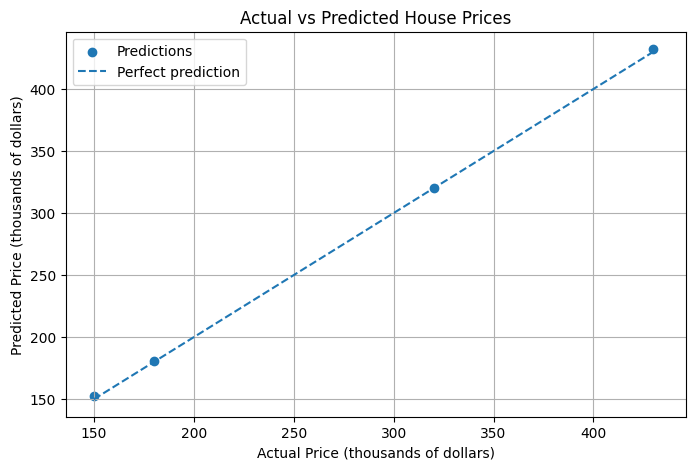

In [ ]:
# Actual vs Predicted visualization

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, label="Predictions")

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect prediction",
)

plt.xlabel("Actual Price (thousands of dollars)")
plt.ylabel("Predicted Price (thousands of dollars)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predict the price of a new house


size = float(input("Enter house size in sqft: "))

new_house = pd.DataFrame({"Size_sqft": [size]})

prediction = model.predict(new_house)[0]

print(f"Predicted price: ${prediction * 1000:,.2f}")

Predicted price: $376,189.76


In [ ]:
# Interactive prediction with input validation

try:
    size = float(input("Enter house size in square feet: "))

    if size <= 0:
        print("Error: House size must be greater than zero.")

    elif size < 800 or size > 3000:
        print("Warning: This size is outside our training data range.")

        new_house = pd.DataFrame({"Size_sqft": [size]})

        prediction = model.predict(new_house)[0]
        print(f"Estimated price: ${prediction * 1000:,.2f}")

    else:
        new_house = pd.DataFrame({"Size_sqft": [size]})

        prediction = model.predict(new_house)[0]

        print("\n--- House Price Prediction ---")
        print(f"House size: {size:,.0f} sq ft")
        print(f"Predicted price: ${prediction * 1000:,.2f}")

except ValueError:
    print("Error: Please enter a valid number.")


--- House Price Prediction ---
House size: 2,400 sq ft
Predicted price: $376,189.76


In [ ]:
# Save the trained model

import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
